In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/ab_test_clean.csv')

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df['most_ads_day'] = pd.Categorical(df['most_ads_day'], categories=day_order, ordered=True)
    
df['ads_bucket'] = pd.cut(df['total_ads'], bins=[0,4,13,27,57,np.inf],
                          labels=['1-4','5-13','14-27','28-57','58+'])

df["time_band"] = pd.cut(df["most_ads_hour"], bins=[-1, 11, 17, 23],
                         labels=["Overnight/Morning (0-11)", "Afternoon (12-17)", "Evening (18-23)"])

In [14]:
def segment_lift(data, col):
    rows = []
    for value, grp in data.groupby(col, observed=True):
        ad = grp[grp['test_group'] == 'ad']['converted']
        psa = grp[grp['test_group'] == 'psa']['converted']

        diff = ad.mean() - psa.mean()
        se = np.sqrt(ad.mean() * (1 - ad.mean()) / len(ad) +
                     psa.mean() * (1 - psa.mean()) / len(psa))
        rows.append({
            "segment": value,
            "ad_users": len(ad),
            "psa_users": len(psa),
            "psa_conversions": int(psa.sum()),
            "ad_rate_%": round(ad.mean() * 100, 2),
            "psa_rate_%": round(psa.mean() * 100, 2),
            "lift_pp": round(diff * 100, 2),
            "ci_low": round((diff - 1.96 * se) * 100, 2),
            "ci_high": round((diff + 1.96 * se) * 100, 2),
        })
    return pd.DataFrame(rows)

In [15]:
by_day = segment_lift(df, 'most_ads_day')
by_day

,segment,ad_users,psa_users,psa_conversions,ad_rate_%,psa_rate_%,lift_pp,ci_low,ci_high
0,Monday,83571,3502,79,3.32,2.26,1.07,0.56,1.57
1,Tuesday,74572,2907,42,3.04,1.44,1.60,1.15,2.05
2,Wednesday,77418,3490,55,2.54,1.58,0.96,0.53,1.39
3,Thursday,79077,3905,79,2.16,2.02,0.14,-0.31,0.59
4,Friday,88805,3803,62,2.25,1.63,0.62,0.20,1.03
5,Saturday,78802,2858,40,2.13,1.40,0.73,0.29,1.17
6,Sunday,82332,3059,63,2.46,2.06,0.40,-0.11,0.92


In [16]:
by_time = segment_lift(df, "time_band")
by_time

,segment,ad_users,psa_users,psa_conversions,ad_rate_%,psa_rate_%,lift_pp,ci_low,ci_high
0,Overnight/Morning (0-11),155628,6462,73,2.02,1.13,0.89,0.62,1.16
1,Afternoon (12-17),246925,10914,220,2.77,2.02,0.75,0.48,1.02
2,Evening (18-23),162024,6148,127,2.74,2.07,0.68,0.31,1.04


In [17]:
by_ads = segment_lift(df, "ads_bucket")
by_ads

,segment,ad_users,psa_users,psa_conversions,ad_rate_%,psa_rate_%,lift_pp,ci_low,ci_high
0,1-4,141938,6582,13,0.24,0.20,0.04,-0.07,0.15
1,5-13,144957,6019,38,0.51,0.63,-0.12,-0.32,0.09
2,14-27,137483,5274,66,1.19,1.25,-0.07,-0.37,0.24
3,28-57,85178,3224,99,4.32,3.07,1.25,0.64,1.86
4,58+,55021,2425,204,14.60,8.41,6.19,5.04,7.33


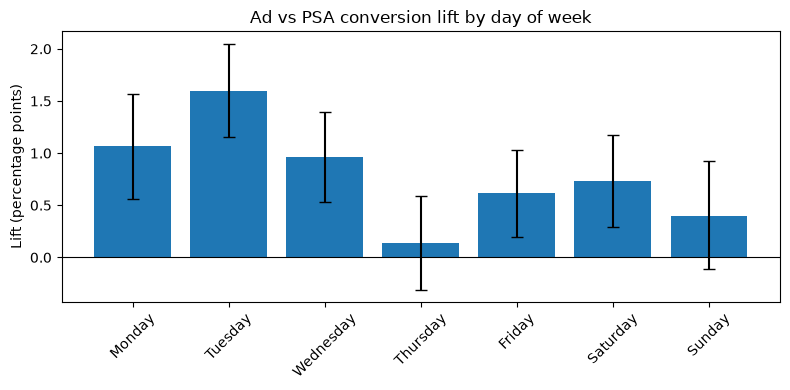

In [18]:
fig, ax = plt.subplots(figsize=(8,4))

errors = [by_day['lift_pp'] - by_day['ci_low'], by_day['ci_high'] - by_day['lift_pp']]
ax.bar(by_day['segment'].astype(str), by_day['lift_pp'], yerr=errors, capsize=4)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Lift (percentage points)')
ax.set_title('Ad vs PSA conversion lift by day of week')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../reports/lift_by_daya.png', dpi=150)
plt.show()

In [19]:
n_ad = (df["test_group"] == "ad").sum()
n_psa = (df["test_group"] == "psa").sum()
p_ad = df.loc[df["test_group"] == "ad", "converted"].mean()
p_psa = df.loc[df["test_group"] == "psa", "converted"].mean()

diff = p_ad - p_psa
se = np.sqrt(p_ad * (1 - p_ad) / n_ad + p_psa * (1 - p_psa) / n_psa)

extra = diff * n_ad
extra_low = (diff - 1.96 * se) * n_ad
extra_high = (diff + 1.96 * se) * n_ad

print("estimated extra conversions:", round(extra))
print("95% range:", round(extra_low), "to", round(extra_high))

estimated extra conversions: 4343
95% range: 3360 to 5326


In [20]:
value_per_conversion = 50

print("estimated value:", round(extra * value_per_conversion))
print("range:", round(extra_low * value_per_conversion), "to", round(extra_high * value_per_conversion))

estimated value: 217149
range: 167987 to 266311


In [21]:
import statsmodels.formula.api as smf
from scipy.stats import chi2

df["converted_int"] = df["converted"].astype(int)
df["is_ad"] = (df["test_group"] == "ad").astype(int)

# model without vs with an interaction between ad group and ads bucket
base = smf.logit("converted_int ~ is_ad + C(ads_bucket)", data=df).fit(disp=0)
inter = smf.logit("converted_int ~ is_ad * C(ads_bucket)", data=df).fit(disp=0)

lr_stat = 2 * (inter.llf - base.llf)
dof = inter.df_model - base.df_model
print("LR statistic:", round(lr_stat, 1), "| p-value:", chi2.sf(lr_stat, dof))

LR statistic: 32.6 | p-value: 1.412387403452373e-06


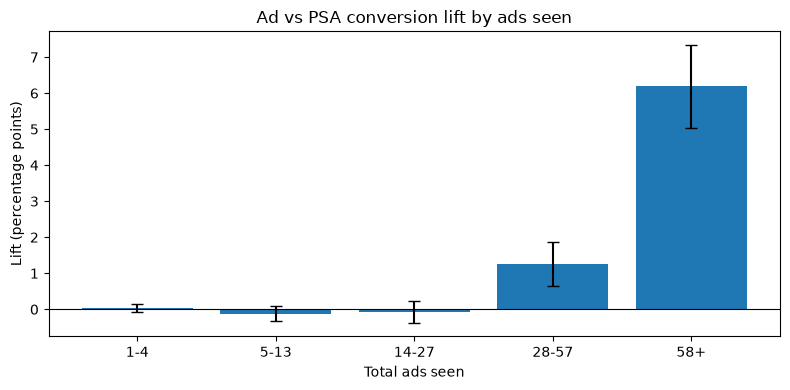

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))

errors = [by_ads["lift_pp"] - by_ads["ci_low"], by_ads["ci_high"] - by_ads["lift_pp"]]
ax.bar(by_ads["segment"].astype(str), by_ads["lift_pp"], yerr=errors, capsize=4)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Total ads seen")
ax.set_ylabel("Lift (percentage points)")
ax.set_title("Ad vs PSA conversion lift by ads seen")
plt.tight_layout()

plt.savefig("../reports/lift_by_ads_seen.png", dpi=150)
plt.show()